<a href="https://colab.research.google.com/github/dharshini-s1812/instacart-market-basket-analysis/blob/main/notebooks/01_SQL_Extraction_and_Aggregation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Instacart Market Basket Analysis — Part 1: SQL Extraction & Aggregation

**Pipeline:** `SQL (this notebook)` → `pandas (Notebook 2)` → `Tableau`

## Project goal
> *How can Instacart increase customer retention and basket size by understanding how customers order and reorder?*

## Role of this notebook
SQL is used as the **extraction and aggregation layer**: it loads the raw CSVs into a relational database, validates them, and builds compact summary tables that answer the descriptive questions. The heavier analytics (feature engineering, basket analysis, clustering) happen in **Notebook 2** with pandas.

## Business questions answered here
| # | Question | SQL techniques shown |
|---|----------|----------------------|
| 1 | When do customers order (day × hour)? | `GROUP BY`, `JOIN` |
| 2 | How often do customers come back? | Window functions (`SUM() OVER`), cumulative % |
| 3 | Which departments / aisles have the stickiest products? | Multi-table `JOIN`, `HAVING` |
| 4 | Which products lead each department? | CTE + `RANK()` |
| 5 | How big are baskets, and do they grow as users mature? | `CASE WHEN`, CTE + `LAG()` |
| 6 | Who are our customers, in numbers? | CTE → user-level feature table |

## Dataset notes
* Source: Instacart Online Grocery Shopping Dataset 2017 (Kaggle) — ~3.4M orders, ~32M order-product rows, ~206K users.
* **No prices, no real dates, no revenue.** This is a *behavioral* analysis (frequency, timing, reordering, basket composition).
* `eval_set` is `prior` (history), `train` or `test`. All behavioral analysis uses **`prior`** orders only.

## Contents
1. Setup
2. Load CSVs into SQLite
3. Indexes & data-quality checks
4. Materialized helper tables
5. Ordering patterns
6. Reorder behaviour
7. Basket size
8. User-level feature table
9. Export for pandas / Tableau

## 1. Setup
Mount Google Drive (Colab) and define paths.

> **Performance note:** the SQLite database is created on Colab's *local* disk (`/content`) because SQLite on a mounted Drive is very slow. The final CSV outputs are saved back to Drive so they persist.

In [ ]:
import os
import time
import sqlite3

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab - using local paths.')

PROJECT_PATH = '/content/drive/MyDrive/Instacart_Market_Basket_Analysis'
DATA_PATH    = os.path.join(PROJECT_PATH, 'data')
OUTPUT_PATH  = os.path.join(PROJECT_PATH, 'outputs')   # summary tables for pandas / Tableau
DB_PATH      = '/content/instacart.db'                 # local disk = much faster than Drive

os.makedirs(OUTPUT_PATH, exist_ok=True)

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid')

print(os.listdir(DATA_PATH))

Mounted at /content/drive
['aisles.csv', 'departments.csv', 'order_products__prior.csv', 'order_products__train.csv', 'orders.csv', 'products.csv', 'processed']


## 2. Load CSVs into SQLite

The large tables are loaded **in chunks** so they never need to fit in memory at once. The loader is *idempotent*: if a table already exists in the database it is skipped, so you can safely re-run the notebook.

> ⏱ `order_products__prior` has ~32M rows, so expect roughly **5–15 minutes** the first time.

In [ ]:
conn = sqlite3.connect(DB_PATH)

# Speed up bulk loading (safe here: the DB can always be rebuilt from the CSVs)
conn.execute('PRAGMA journal_mode = OFF;')
conn.execute('PRAGMA synchronous = OFF;')
conn.execute('PRAGMA temp_store = MEMORY;')
conn.execute('PRAGMA cache_size = -500000;')   # ~500 MB page cache


def run_query(sql, params=None):
    """Run a SELECT and return a DataFrame, printing the elapsed time."""
    start = time.time()
    df = pd.read_sql_query(sql, conn, params=params)
    print(f'[{time.time() - start:5.1f}s] {len(df):,} rows')
    return df


def execute(sql):
    """Run DDL / DML (CREATE, DROP, INSERT ...), printing the elapsed time."""
    start = time.time()
    conn.execute(sql)
    conn.commit()
    print(f'[{time.time() - start:5.1f}s] done')


def table_exists(name):
    row = conn.execute(
        "SELECT name FROM sqlite_master WHERE type='table' AND name=?", (name,)
    ).fetchone()
    return row is not None


def load_csv_to_sqlite(table, filename, chunksize=500_000):
    if table_exists(table):
        print(f'- {table:<24} already loaded, skipping')
        return
    start = time.time()
    path = os.path.join(DATA_PATH, filename)
    try:
        for chunk in pd.read_csv(path, chunksize=chunksize):
            chunk.to_sql(table, conn, if_exists='append', index=False)
        conn.commit()
    except BaseException:
        conn.execute(f'DROP TABLE IF EXISTS {table}')   # never leave a half-loaded table behind
        raise
    print(f'- {table:<24} loaded in {time.time() - start:6.1f}s')


FILES = {
    'aisles':                'aisles.csv',
    'departments':           'departments.csv',
    'products':              'products.csv',
    'orders':                'orders.csv',
    'order_products__train': 'order_products__train.csv',
    'order_products__prior': 'order_products__prior.csv',
}

for table, filename in FILES.items():
    load_csv_to_sqlite(table, filename)

- aisles                   loaded in    0.3s
- departments              loaded in    0.3s
- products                 loaded in    0.8s
- orders                   loaded in   15.3s
- order_products__train    loaded in    4.0s
- order_products__prior    loaded in  102.7s


### Sanity check — row counts
Compare the loaded counts with the published size of the full Instacart dataset to confirm nothing was lost in the load.

In [ ]:
EXPECTED = {
    'aisles': 134, 'departments': 21, 'products': 49_688, 'orders': 3_421_083,
    'order_products__train': 1_384_617, 'order_products__prior': 32_434_489,
}

rows = []
for table in FILES:
    n = conn.execute(f'SELECT COUNT(*) FROM {table}').fetchone()[0]
    rows.append({'table': table, 'rows_loaded': n, 'expected_full_dataset': EXPECTED[table],
                 'match': n == EXPECTED[table]})
pd.DataFrame(rows)

,table,rows_loaded,expected_full_dataset,match
0,aisles,134,134,True
1,departments,21,21,True
2,products,49688,49688,True
3,orders,3421083,3421083,True
4,order_products__train,1384617,1384617,True
5,order_products__prior,32434489,32434489,True


## 3. Indexes & data-quality checks

### 3.1 Indexes
Without indexes, every join on a 32M-row table is a full scan. Indexing the join keys (`order_id`, `product_id`, `user_id`) is the single biggest performance win in this notebook.

In [ ]:
INDEXES = [
    'CREATE INDEX IF NOT EXISTS idx_orders_order_id   ON orders(order_id)',
    'CREATE INDEX IF NOT EXISTS idx_orders_user_id    ON orders(user_id)',
    'CREATE INDEX IF NOT EXISTS idx_prior_order_id    ON order_products__prior(order_id)',
    'CREATE INDEX IF NOT EXISTS idx_prior_product_id  ON order_products__prior(product_id)',
    'CREATE INDEX IF NOT EXISTS idx_products_id       ON products(product_id)',
]
for stmt in INDEXES:
    print(stmt.split(' ON ')[0].replace('CREATE INDEX IF NOT EXISTS ', 'index: '), end='  ')
    execute(stmt)

conn.execute('ANALYZE')   # refresh planner statistics

index: idx_orders_order_id    [  6.7s] done
index: idx_orders_user_id     [  2.1s] done
index: idx_prior_order_id     [ 27.7s] done
index: idx_prior_product_id   [ 86.6s] done
index: idx_products_id        [  0.1s] done


### 3.2 Data-quality checks
What we verify and why:

* **`days_since_prior_order` NULLs** should occur *only* on a user's first order (nothing precedes it).
* **Cap at 30** — the dataset top-codes the gap at 30 days, so "30" really means "30 or more". This matters when computing averages.
* **Orphan keys** — every `product_id` used in an order must exist in `products`.
* **Placeholder categories** — Instacart has `missing` / `other` aisle and department values that should usually be excluded from rankings.

In [ ]:
checks = {
    'NULL days_since_prior_order on FIRST orders (expected: all first orders)':
        "SELECT COUNT(*) FROM orders WHERE days_since_prior_order IS NULL AND order_number = 1",
    'NULL days_since_prior_order on NON-first orders (expected: 0)':
        "SELECT COUNT(*) FROM orders WHERE days_since_prior_order IS NULL AND order_number > 1",
    'Max days_since_prior_order (expected: 30 = top-coded)':
        "SELECT MAX(days_since_prior_order) FROM orders",
    'Order-product rows whose product_id is missing from products (expected: 0)':
        """SELECT COUNT(*) FROM order_products__prior op
           LEFT JOIN products p USING (product_id) WHERE p.product_id IS NULL""",
    'Order-product rows whose order_id is missing from orders (expected: 0)':
        """SELECT COUNT(*) FROM order_products__prior op
           LEFT JOIN orders o USING (order_id) WHERE o.order_id IS NULL""",
}

pd.DataFrame(
    [{'check': name, 'result': conn.execute(sql).fetchone()[0]} for name, sql in checks.items()]
)

,check,result
0,NULL days_since_prior_order on FIRST orders (e...,"206,209.0000"
1,NULL days_since_prior_order on NON-first order...,0.0000
2,Max days_since_prior_order (expected: 30 = top...,30.0000
3,Order-product rows whose product_id is missing...,0.0000
4,Order-product rows whose order_id is missing f...,0.0000


In [ ]:
# Orders by evaluation set + placeholder categories
display(run_query("""
    SELECT eval_set, COUNT(*) AS n_orders, COUNT(DISTINCT user_id) AS n_users
    FROM orders GROUP BY eval_set
"""))

display(run_query("""
    SELECT 'department' AS level, department AS name FROM departments WHERE department IN ('missing', 'other')
    UNION ALL
    SELECT 'aisle', aisle FROM aisles WHERE aisle IN ('missing', 'other')
"""))

[  2.6s] 3 rows


,eval_set,n_orders,n_users
0,prior,3214874,206209
1,test,75000,75000
2,train,131209,131209


[  0.0s] 4 rows


,level,name
0,department,other
1,department,missing
2,aisle,other
3,aisle,missing


## 4. Materialized helper tables

Several analyses need *per-product* or *per-order* totals. Computing them from the 32M-row table every time would be slow, so we aggregate **once**, store the result as a table, and reuse it. This is the same idea as a staging layer in a data warehouse.

| Table | Grain | Columns |
|-------|-------|---------|
| `product_stats` | one row per product | `n_orders`, `n_reorders`, `reorder_rate` |
| `order_sizes`   | one row per order   | `basket_size`, `n_reordered` |

In [ ]:
execute('DROP TABLE IF EXISTS product_stats')
execute("""
    CREATE TABLE product_stats AS
    SELECT
        product_id,
        COUNT(*)                              AS n_orders,
        SUM(reordered)                        AS n_reorders,
        ROUND(1.0 * SUM(reordered) / COUNT(*), 4) AS reorder_rate
    FROM order_products__prior
    GROUP BY product_id
""")
execute('CREATE INDEX idx_product_stats_id ON product_stats(product_id)')

[  0.0s] done
[ 73.8s] done
[  0.0s] done


In [ ]:
execute('DROP TABLE IF EXISTS order_sizes')
execute("""
    CREATE TABLE order_sizes AS
    SELECT
        order_id,
        COUNT(*)       AS basket_size,
        SUM(reordered) AS n_reordered
    FROM order_products__prior
    GROUP BY order_id
""")
execute('CREATE INDEX idx_order_sizes_id ON order_sizes(order_id)')

[  0.0s] done
[ 11.0s] done
[  1.4s] done


## 5. Ordering patterns

### 5.1 When do customers order? (day of week × hour)
**Why it matters:** order timing drives delivery-slot capacity, shopper staffing, and the best moment to send promotions.

> `order_dow` is coded 0–6 but the dataset does **not** document which number is which weekday, so we keep the raw codes instead of guessing labels.

In [ ]:
orders_dow_hour = run_query("""
    SELECT
        o.order_dow,
        o.order_hour_of_day,
        COUNT(*)                                          AS n_orders,
        ROUND(AVG(s.basket_size), 2)                      AS avg_basket_size,
        ROUND(1.0 * SUM(s.n_reordered) / SUM(s.basket_size), 4) AS reorder_rate
    FROM orders o
    JOIN order_sizes s USING (order_id)
    WHERE o.eval_set = 'prior'
    GROUP BY o.order_dow, o.order_hour_of_day
    ORDER BY o.order_dow, o.order_hour_of_day
""")
orders_dow_hour.head()

[ 14.5s] 168 rows


,order_dow,order_hour_of_day,n_orders,avg_basket_size,reorder_rate
0,0,0,3692,10.5300,0.5765
1,0,1,2235,10.0800,0.5518
2,0,2,1299,9.8000,0.5523
3,0,3,888,9.9700,0.5694
4,0,4,750,11.1600,0.5466


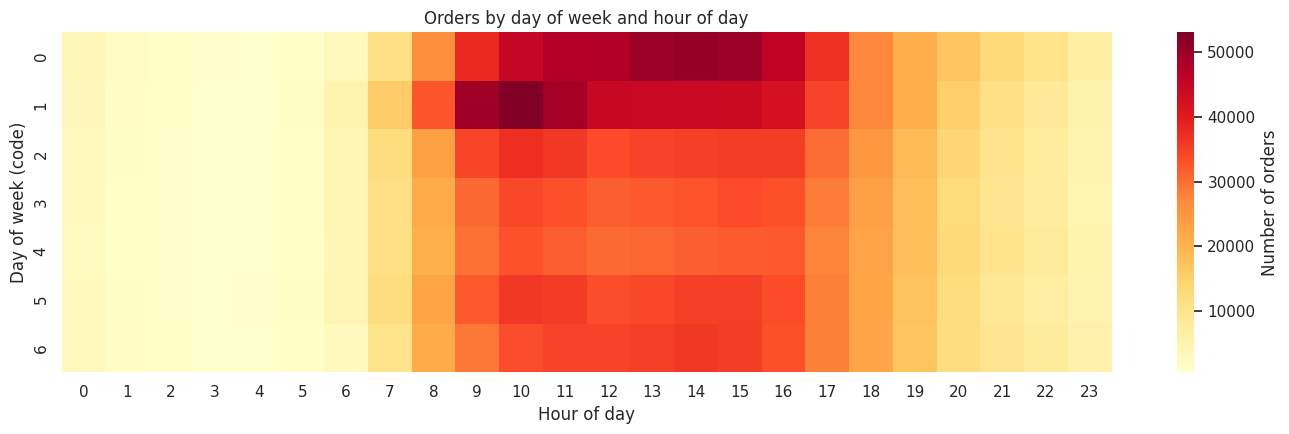

In [ ]:
heat = orders_dow_hour.pivot(index='order_dow', columns='order_hour_of_day', values='n_orders')

plt.figure(figsize=(14, 4.5))
sns.heatmap(heat, cmap='YlOrRd', cbar_kws={'label': 'Number of orders'})
plt.title('Orders by day of week and hour of day')
plt.xlabel('Hour of day')
plt.ylabel('Day of week (code)')
plt.tight_layout()
plt.show()

**Insight:**

Order demand is highest on days 0 and 1, particularly between 9 AM and 4 PM, with the strongest peak around 10 AM on day 1. Demand is concentrated during daytime hours rather than being evenly distributed throughout the day. Orders are relatively low during late-night and early-morning hours.

**Business implications:**
- **Staffing:** Allocate more delivery and operational staff during peak daytime hours to handle increased demand.
- **Promotions:** Run targeted offers during quieter hours to encourage customers to order outside peak periods.
- **Capacity planning:** Ensure sufficient delivery capacity during high-demand days and hours to reduce delays.

### 5.2 How often do customers come back?
The distribution of `days_since_prior_order` reveals shopping *rhythms*. We add a **cumulative %** with a window function to see how quickly most users return.

> ⚠️ The value **30** is top-coded ("30 or more days"), so expect an artificial spike there. Treat it as a ceiling, not an exact gap.

In [ ]:
days_dist = run_query("""
    SELECT
        CAST(days_since_prior_order AS INTEGER)  AS days_since_prior_order,
        COUNT(*)                                 AS n_orders,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_orders,
        ROUND(100.0 * SUM(COUNT(*)) OVER (ORDER BY days_since_prior_order)
                    / SUM(COUNT(*)) OVER (), 2)            AS cumulative_pct
    FROM orders
    WHERE days_since_prior_order IS NOT NULL
    GROUP BY days_since_prior_order
    ORDER BY days_since_prior_order
""")
days_dist

[  4.4s] 31 rows


,days_since_prior_order,n_orders,pct_of_orders,cumulative_pct
0,0,67755,2.1100,2.1100
1,1,145247,4.5200,6.6300
2,2,193206,6.0100,12.6400
3,3,217005,6.7500,19.3900
4,4,221696,6.9000,26.2800
5,5,214503,6.6700,32.9500
6,6,240013,7.4700,40.4200
7,7,320608,9.9700,50.3900
8,8,181717,5.6500,56.0400
9,9,118188,3.6800,59.7200


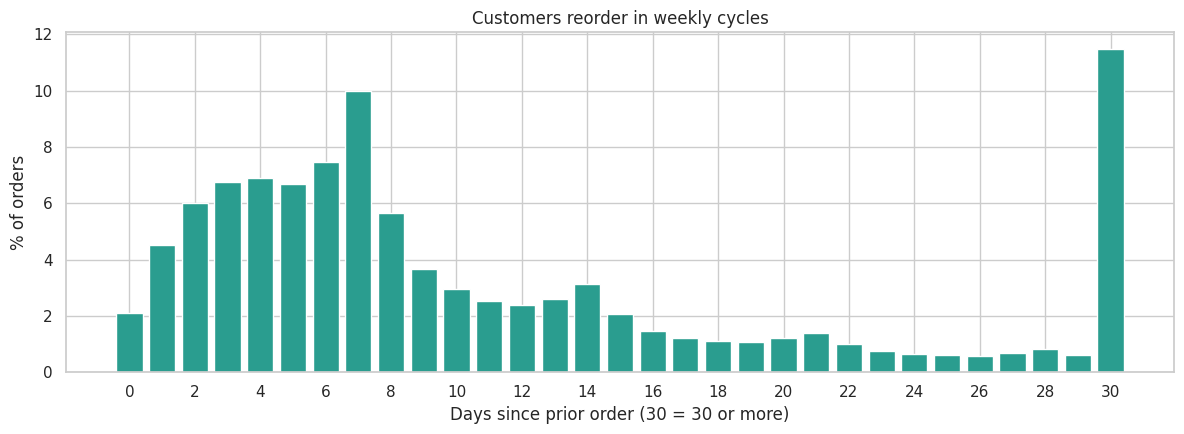

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(days_dist['days_since_prior_order'], days_dist['pct_of_orders'], color='#2a9d8f')
ax.set_xlabel('Days since prior order (30 = 30 or more)')
ax.set_ylabel('% of orders')
ax.set_title('Customers reorder in weekly cycles')
ax.set_xticks(range(0, 31, 2))
plt.tight_layout()
plt.show()

Approximately half of customer reorders occur within the first seven days, indicating strong short-term purchasing activity. A noticeable peak on day 7 suggests weekly purchasing habits among customers. However, a substantial proportion of customers also reorder after 30 days or more, indicating differences in purchasing frequency.

## 6. Reorder behaviour

A **reorder** means the user has bought that product before. Reorder rate is the best behavioural proxy for *loyalty* and *habit* in this dataset.

### 6.1 Reorder rate by department
Joins `product_stats → products → departments`. Because `product_stats` is pre-aggregated, this query is fast.

In [ ]:
dept_reorder = run_query("""
    SELECT
        d.department,
        COUNT(*)                                            AS n_products,
        SUM(ps.n_orders)                                    AS items_ordered,
        SUM(ps.n_reorders)                                  AS items_reordered,
        ROUND(1.0 * SUM(ps.n_reorders) / SUM(ps.n_orders), 4) AS reorder_rate
    FROM product_stats ps
    JOIN products    p USING (product_id)
    JOIN departments d USING (department_id)
    WHERE d.department NOT IN ('missing', 'other')
    GROUP BY d.department
    ORDER BY reorder_rate DESC
""")
dept_reorder

[  0.2s] 19 rows


,department,n_products,items_ordered,items_reordered,reorder_rate
0,dairy eggs,3448,5414016,3627221,0.6700
1,beverages,4363,2690129,1757892,0.6535
2,produce,1684,9479291,6160710,0.6499
3,bakery,1516,1176787,739188,0.6281
4,deli,1322,1051249,638864,0.6077
5,pets,972,97724,58760,0.6013
6,babies,1081,423802,245369,0.5790
7,bulk,38,34573,19950,0.5770
8,snacks,6263,2887550,1657973,0.5742
9,alcohol,1054,153696,87595,0.5699


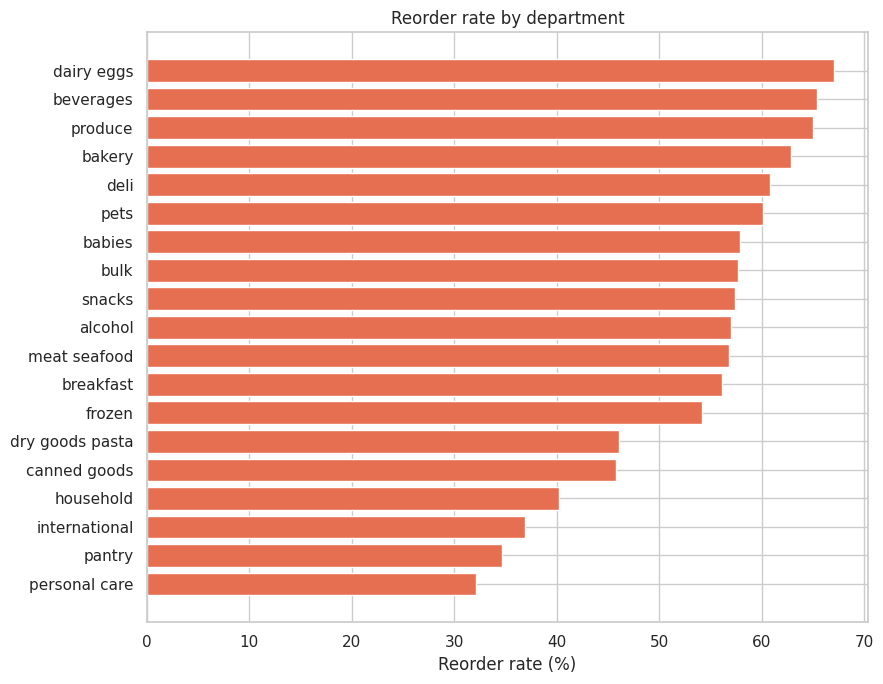

In [ ]:
plot_df = dept_reorder.sort_values('reorder_rate')
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(plot_df['department'], plot_df['reorder_rate'] * 100, color='#e76f51')
ax.set_xlabel('Reorder rate (%)')
ax.set_title('Reorder rate by department')
plt.tight_layout()
plt.show()

### 6.2 Reorder rate by aisle (with a volume threshold)
Small aisles can show extreme rates by chance. `HAVING` keeps only aisles with at least **100,000 items ordered**, so every rate we report rests on a large sample.

In [ ]:
aisle_reorder = run_query("""
    SELECT
        a.aisle,
        d.department,
        COUNT(*)                                            AS n_products,
        SUM(ps.n_orders)                                    AS items_ordered,
        ROUND(1.0 * SUM(ps.n_reorders) / SUM(ps.n_orders), 4) AS reorder_rate
    FROM product_stats ps
    JOIN products    p USING (product_id)
    JOIN aisles      a USING (aisle_id)
    JOIN departments d USING (department_id)
    WHERE a.aisle NOT IN ('missing', 'other')
    GROUP BY a.aisle, d.department
    HAVING SUM(ps.n_orders) >= 100000
    ORDER BY reorder_rate DESC
""")
display(aisle_reorder.head(10))
print('Lowest reorder-rate aisles (customers explore here):')
aisle_reorder.tail(10)

[  0.3s] 66 rows


,aisle,department,n_products,items_ordered,reorder_rate
0,milk,dairy eggs,243,891015,0.7814
1,water seltzer sparkling water,beverages,344,841533,0.7296
2,fresh fruits,produce,382,3642188,0.7181
3,eggs,dairy eggs,125,452134,0.7054
4,soy lactosefree,dairy eggs,293,638253,0.6926
5,packaged produce,produce,32,276028,0.6907
6,yogurt,dairy eggs,1026,1452343,0.6865
7,cream,dairy eggs,161,318002,0.6850
8,bread,bakery,557,584834,0.6702
9,refrigerated,beverages,673,575881,0.6633


Lowest reorder-rate aisles (customers explore here):


,aisle,department,n_products,items_ordered,reorder_rate
56,soup broth bouillon,canned goods,737,346464,0.4214
57,canned jarred vegetables,canned goods,487,297037,0.4211
58,grains rice dried goods,dry goods pasta,336,144189,0.3983
59,doughs gelatins bake mixes,pantry,463,106089,0.3928
60,asian foods,international,605,166607,0.3511
61,oils vinegars,pantry,375,245466,0.3508
62,condiments,pantry,466,222049,0.3086
63,baking ingredients,pantry,623,326692,0.3051
64,cleaning products,household,655,118477,0.2885
65,spices seasonings,pantry,797,212092,0.1524


### 6.3 Top products per department — CTE + `RANK()`
`RANK() OVER (PARTITION BY department ...)` ranks products *within* each department, something a plain `GROUP BY` cannot do. The CTE keeps the logic readable.

In [ ]:
top_products = run_query("""
    WITH ranked AS (
        SELECT
            d.department,
            p.product_name,
            ps.n_orders,
            ps.reorder_rate,
            RANK() OVER (PARTITION BY d.department ORDER BY ps.n_orders DESC) AS rank_in_department
        FROM product_stats ps
        JOIN products    p USING (product_id)
        JOIN departments d USING (department_id)
        WHERE d.department NOT IN ('missing', 'other')
    )
    SELECT * FROM ranked
    WHERE rank_in_department <= 10
    ORDER BY department, rank_in_department
""")
top_products[top_products['rank_in_department'] <= 3].head(15)

[  0.4s] 190 rows


,department,product_name,n_orders,reorder_rate,rank_in_department
0,alcohol,Sauvignon Blanc,8246,0.6812,1
1,alcohol,Chardonnay,6153,0.6875,2
2,alcohol,Cabernet Sauvignon,6115,0.6029,3
10,babies,Baby Food Stage 2 Blueberry Pear & Purple Carrot,8793,0.6465,1
11,babies,Spinach Peas & Pear Stage 2 Baby Food,8035,0.6447,2
12,babies,Gluten Free SpongeBob Spinach Littles,7083,0.6501,3
20,bakery,100% Whole Wheat Bread,60816,0.7372,1
21,bakery,Organic Bread with 21 Whole Grains,23006,0.7158,2
22,bakery,Ezekiel 4:9 Bread Organic Sprouted Whole Grain,17789,0.6290,3
30,beverages,Sparkling Water Grapefruit,75886,0.7711,1


### 6.4 Most "habit-forming" vs. most "exploratory" products
Only products with **≥ 500 orders** are considered, so a product bought twice and reordered once (50%) cannot dominate the list.

In [ ]:
habit_products = run_query("""
    SELECT p.product_name, a.aisle, d.department, ps.n_orders, ps.reorder_rate
    FROM product_stats ps
    JOIN products    p USING (product_id)
    JOIN aisles      a USING (aisle_id)
    JOIN departments d USING (department_id)
    WHERE ps.n_orders >= 500
    ORDER BY ps.reorder_rate DESC
    LIMIT 20
""")
explore_products = run_query("""
    SELECT p.product_name, a.aisle, d.department, ps.n_orders, ps.reorder_rate
    FROM product_stats ps
    JOIN products    p USING (product_id)
    JOIN aisles      a USING (aisle_id)
    JOIN departments d USING (department_id)
    WHERE ps.n_orders >= 500
    ORDER BY ps.reorder_rate ASC
    LIMIT 20
""")
print('Highest reorder rate (habit products)')
display(habit_products.head(10))
print('Lowest reorder rate (discovery products)')
explore_products.head(10)

[  0.2s] 20 rows
[  0.2s] 20 rows
Highest reorder rate (habit products)


,product_name,aisle,department,n_orders,reorder_rate
0,Half And Half Ultra Pasteurized,milk,dairy eggs,2921,0.8617
1,Whole Organic Omega 3 Milk,milk,dairy eggs,9108,0.8602
2,Organic Lactose Free Whole Milk,soy lactosefree,dairy eggs,8477,0.8590
3,Organic Homogenized Whole Milk,milk,dairy eggs,3970,0.8577
4,Ultra-Purified Water,water seltzer sparkling water,beverages,1489,0.8576
5,"Milk, Organic, Vitamin D",milk,dairy eggs,20198,0.8543
6,Organic Reduced Fat Milk,milk,dairy eggs,35663,0.8507
7,Goat Milk,milk,dairy eggs,5185,0.8500
8,Banana,fresh fruits,produce,472565,0.8435
9,Organic Whole Milk,milk,dairy eggs,9842,0.8412


Lowest reorder rate (discovery products)


,product_name,aisle,department,n_orders,reorder_rate
0,Ground Cloves,spices seasonings,pantry,647,0.0247
1,Ground Allspice,spices seasonings,pantry,605,0.0264
2,Organic Allspice,spices seasonings,pantry,579,0.0311
3,Organic Ground Nutmeg,spices seasonings,pantry,1055,0.0351
4,Whole Cloves,spices seasonings,pantry,649,0.0385
5,Round Toothpicks,plates bowls cups flatware,household,587,0.0409
6,Dill Weed,spices seasonings,pantry,925,0.0497
7,Ground Nutmeg,spices seasonings,pantry,603,0.0498
8,Fennel Seed,spices seasonings,pantry,850,0.0506
9,Cumin Seed,spices seasonings,pantry,1009,0.0545


Product reorder behaviour reveals two distinct purchasing patterns. Everyday essentials, particularly dairy products, beverages and fresh produce, demonstrate high repeat purchasing, making them suitable for replenishment reminders and Buy Again recommendations. In contrast, spices, seasonings and certain household products exhibit low reorder rates, suggesting less frequent repeat purchases. These categories present opportunities for product discovery, cross-selling and targeted promotions.

## 7. Basket size

### 7.1 Basket-size distribution with `CASE WHEN` buckets

In [ ]:
basket_dist = run_query("""
    SELECT
        CASE
            WHEN basket_size <=  5 THEN '01-05 items'
            WHEN basket_size <= 10 THEN '06-10 items'
            WHEN basket_size <= 20 THEN '11-20 items'
            WHEN basket_size <= 30 THEN '21-30 items'
            WHEN basket_size <= 50 THEN '31-50 items'
            ELSE '51+ items'
        END                                              AS basket_bucket,
        COUNT(*)                                         AS n_orders,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_orders
    FROM order_sizes
    GROUP BY basket_bucket
    ORDER BY MIN(basket_size)
""")
basket_dist

[  3.8s] 6 rows


,basket_bucket,n_orders,pct_of_orders
0,01-05 items,1001179,31.1400
1,06-10 items,1000952,31.1400
2,11-20 items,909333,28.2900
3,21-30 items,237738,7.3900
4,31-50 items,62591,1.9500
5,51+ items,3081,0.1000


### 7.2 Do baskets grow as users mature? — CTE + `LAG()`
`LAG()` looks at the *same user's previous order*, giving a within-user change in basket size. Averaging that change by order number shows whether customers add more items as they build trust in the service.

Order numbers above 20 are grouped together to keep the sample size large per row.

In [ ]:
basket_evolution = run_query("""
    WITH seq AS (
        SELECT
            o.user_id,
            o.order_number,
            s.basket_size,
            LAG(s.basket_size) OVER (
                PARTITION BY o.user_id ORDER BY o.order_number
            ) AS prev_basket_size
        FROM orders o
        JOIN order_sizes s USING (order_id)
        WHERE o.eval_set = 'prior'
    )
    SELECT
        MIN(order_number, 20)                               AS order_number_capped,
        COUNT(*)                                            AS n_orders,
        ROUND(AVG(basket_size), 2)                          AS avg_basket_size,
        ROUND(AVG(basket_size - prev_basket_size), 2)       AS avg_change_vs_previous_order
    FROM seq
    GROUP BY order_number_capped
    ORDER BY order_number_capped
""")
basket_evolution

[ 23.1s] 20 rows


,order_number_capped,n_orders,avg_basket_size,avg_change_vs_previous_order
0,1,206209,10.0800,NaN
1,2,206209,9.9300,-0.1400
2,3,206209,9.9400,0.0100
3,4,182223,9.9900,0.0000
4,5,162633,10.0100,0.0000
5,6,146468,10.0500,0.0400
6,7,132618,10.0600,-0.0000
7,8,120918,10.0800,0.0300
8,9,110728,10.1200,0.0600
9,10,101696,10.1200,0.0100


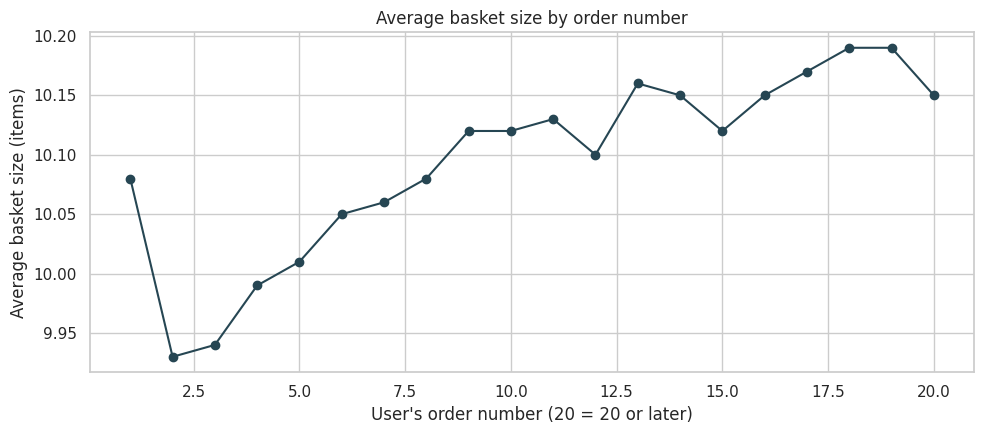

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(basket_evolution['order_number_capped'], basket_evolution['avg_basket_size'],
        marker='o', color='#264653')
ax.set_xlabel("User's order number (20 = 20 or later)")
ax.set_ylabel('Average basket size (items)')
ax.set_title('Average basket size by order number')
plt.tight_layout()
plt.show()

Basket evolution analysis indicates that average customer basket sizes remain relatively stable across successive orders, hovering around 10 items per order. Although a slight upward trend is observed among later orders, the changes are marginal. This suggests that customers generally maintain consistent purchasing quantities rather than significantly increasing their basket sizes as they become repeat customers. E-commerce platforms could focus on personalized cross-selling and complementary product recommendations to encourage incremental basket growth.

## 8. User-level feature table

One row per user summarising their behaviour. This is the **handoff table** to Notebook 2, where it is enriched (favourite department, product diversity, ...) and used for segmentation.

| Feature | Meaning |
|---------|---------|
| `n_orders` | Number of prior orders (engagement) |
| `total_items` | Total items purchased |
| `avg_basket_size` | Average items per order |
| `reorder_ratio` | Share of the user's items that were reorders (habit strength) |
| `avg_days_between_orders` | Average gap between orders, ignoring the first order (NULL) |
| `shopping_rhythm` | Rule-based label from the average gap: Weekly / Bi-weekly / Every ~3 weeks / Monthly |

The rhythm thresholds (≤ 9, ≤ 16, ≤ 23 days) are judgement calls placed between the weekly spikes seen in section 5.2.

In [ ]:
execute('DROP TABLE IF EXISTS user_features')
execute("""
    CREATE TABLE user_features AS
    WITH user_orders AS (
        SELECT
            o.user_id,
            o.order_id,
            o.days_since_prior_order,
            s.basket_size,
            s.n_reordered
        FROM orders o
        JOIN order_sizes s USING (order_id)
        WHERE o.eval_set = 'prior'
    )
    SELECT
        user_id,
        COUNT(*)                                              AS n_orders,
        SUM(basket_size)                                      AS total_items,
        ROUND(AVG(basket_size), 2)                            AS avg_basket_size,
        ROUND(1.0 * SUM(n_reordered) / SUM(basket_size), 4)   AS reorder_ratio,
        ROUND(AVG(days_since_prior_order), 2)                 AS avg_days_between_orders,
        CASE
            WHEN AVG(days_since_prior_order) <=  9 THEN 'Weekly'
            WHEN AVG(days_since_prior_order) <= 16 THEN 'Bi-weekly'
            WHEN AVG(days_since_prior_order) <= 23 THEN 'Every ~3 weeks'
            ELSE 'Monthly'
        END                                                   AS shopping_rhythm
    FROM user_orders
    GROUP BY user_id
""")
execute('CREATE INDEX idx_user_features_id ON user_features(user_id)')

[  0.0s] done
[ 14.1s] done
[  0.2s] done


In [ ]:
user_features = run_query('SELECT * FROM user_features')
display(user_features.head())
display(user_features.describe().T)

[  1.2s] 206,209 rows


,user_id,n_orders,total_items,avg_basket_size,reorder_ratio,avg_days_between_orders,shopping_rhythm
0,1,10,59,5.9000,0.6949,19.5600,Every ~3 weeks
1,2,14,195,13.9300,0.4769,15.2300,Bi-weekly
2,3,12,88,7.3300,0.6250,12.0900,Bi-weekly
3,4,5,18,3.6000,0.0556,13.7500,Bi-weekly
4,5,4,37,9.2500,0.3784,13.3300,Bi-weekly


,count,mean,std,min,25%,50%,75%,max
user_id,"206,209.0000","103,105.0000","59,527.5552",1.0000,"51,553.0000","103,105.0000","154,657.0000","206,209.0000"
n_orders,"206,209.0000",15.5904,16.6548,3.0000,5.0000,9.0000,19.0000,99.0000
total_items,"206,209.0000",157.2894,204.2082,3.0000,39.0000,83.0000,188.0000,"3,725.0000"
avg_basket_size,"206,209.0000",9.9518,5.8636,1.0000,5.7400,8.9300,13.0000,70.2500
reorder_ratio,"206,209.0000",0.4322,0.2121,0.0000,0.2679,0.4286,0.5957,0.9895
avg_days_between_orders,"206,209.0000",15.2096,7.1053,0.0000,9.4200,14.5000,20.2900,30.0000


In [ ]:
rhythm_summary = run_query("""
    SELECT
        shopping_rhythm,
        COUNT(*)                                         AS n_users,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_users,
        ROUND(AVG(n_orders), 1)                          AS avg_orders,
        ROUND(AVG(avg_basket_size), 2)                   AS avg_basket_size,
        ROUND(AVG(reorder_ratio), 3)                     AS avg_reorder_ratio
    FROM user_features
    GROUP BY shopping_rhythm
    ORDER BY MIN(avg_days_between_orders)
""")
rhythm_summary

[  0.4s] 4 rows


,shopping_rhythm,n_users,pct_users,avg_orders,avg_basket_size,avg_reorder_ratio
0,Weekly,47883,23.2200,31.4000,9.9700,0.5560
1,Bi-weekly,70103,34.0000,15.3000,10.1400,0.4660
2,Every ~3 weeks,56211,27.2600,8.4000,10.0000,0.3650
3,Monthly,32012,15.5200,5.1000,9.4300,0.2920


Customer shopping frequency is positively associated with reorder behaviour. Weekly shoppers exhibit a reorder ratio of 55.6%, compared with 29.2% among monthly shoppers. However, average basket sizes remain relatively stable across all shopping-frequency segments, suggesting that purchase frequency, rather than basket size, is the stronger differentiating behavioural feature.

## 9. Export summary tables

Each table is saved as a small CSV in `outputs/`:
* **Notebook 2** reads `sql_user_features.csv`.
* **Tableau** connects to the rest. Never load the 32M-row raw table into Tableau; pre-aggregated tables keep dashboards fast.

In [ ]:
exports = {
    'sql_user_features.csv':    user_features,
    'sql_orders_dow_hour.csv':  orders_dow_hour,
    'sql_days_since_prior.csv': days_dist,
    'sql_department_reorder.csv': dept_reorder,
    'sql_aisle_reorder.csv':    aisle_reorder,
    'sql_top_products.csv':     top_products,
    'sql_habit_products.csv':   habit_products,
    'sql_explore_products.csv': explore_products,
    'sql_basket_distribution.csv': basket_dist,
    'sql_basket_evolution.csv': basket_evolution,
    'sql_rhythm_summary.csv':   rhythm_summary,
}

for filename, df in exports.items():
    df.to_csv(os.path.join(OUTPUT_PATH, filename), index=False)
    print(f'saved {filename:<30} {len(df):>9,} rows')

saved sql_user_features.csv            206,209 rows
saved sql_orders_dow_hour.csv              168 rows
saved sql_days_since_prior.csv              31 rows
saved sql_department_reorder.csv            19 rows
saved sql_aisle_reorder.csv                 66 rows
saved sql_top_products.csv                 190 rows
saved sql_habit_products.csv                20 rows
saved sql_explore_products.csv              20 rows
saved sql_basket_distribution.csv            6 rows
saved sql_basket_evolution.csv              20 rows
saved sql_rhythm_summary.csv                 4 rows


In [ ]:
conn.close()
print('Database connection closed.')

Database connection closed.


## Summary

**What this notebook delivered**
* A validated relational database with indexes on all join keys.
* Two materialized helper tables (`product_stats`, `order_sizes`) that make every later query fast.
* Eleven summary tables covering timing, reorder behaviour, basket size and user-level features.

**Next:** open **Notebook 2 — pandas analysis & segmentation**, which picks up `sql_user_features.csv`, adds behavioural features that are awkward in SQL (favourite department, product diversity), runs aisle-level basket analysis, and builds customer segments.
